In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Load Data

In [2]:
## Read restaurant metadata
df = pd.read_csv("Zomato Restaurant names and Metadata.csv")

## Read reviews data
df1 = pd.read_csv("Zomato Restaurant reviews.csv")

## check
df.head()

,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


## Data Understanding

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Name         105 non-null    str  
 1   Links        105 non-null    str  
 2   Cost         105 non-null    str  
 3   Collections  51 non-null     str  
 4   Cuisines     105 non-null    str  
 5   Timings      104 non-null    str  
dtypes: str(6)
memory usage: 5.0 KB


In [4]:
df.describe()

,Name,Links,Cost,Collections,Cuisines,Timings
count,105,105,105,51,105,104
unique,105,105,29,42,92,77
top,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,500,Food Hygiene Rated Restaurants in Hyderabad,"North Indian, Chinese",11 AM to 11 PM
freq,1,1,13,4,4,6


In [5]:
df.isna().sum()

Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

## Data Cleaning

In [7]:
df = df.drop_duplicates()
df['Cost'] = df['Cost'].str.replace(',','').astype(float)
df.dropna(inplace=True)

In [8]:
df.isna().sum()

Name           0
Links          0
Cost           0
Collections    0
Cuisines       0
Timings        0
dtype: int64

## Data Understanding

In [9]:
df.isna().sum()

Name           0
Links          0
Cost           0
Collections    0
Cuisines       0
Timings        0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 51 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         51 non-null     str    
 1   Links        51 non-null     str    
 2   Cost         51 non-null     float64
 3   Collections  51 non-null     str    
 4   Cuisines     51 non-null     str    
 5   Timings      51 non-null     str    
dtypes: float64(1), str(5)
memory usage: 2.8 KB


In [12]:
df.describe()

,Cost
count,51.000000
mean,1112.745098
std,537.107358
min,350.000000
25%,700.000000
50%,1100.000000
75%,1500.000000
max,2800.000000


## EDA (Visualization)

Part 1 - Metadata EDA (df)

 ## Cost Distribution

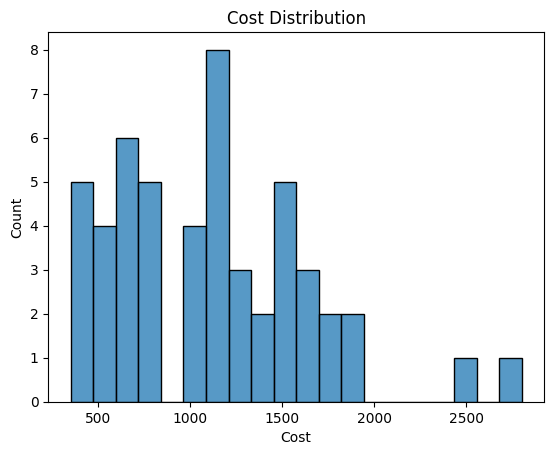

In [13]:
plt.figure()
sns.histplot(df['Cost'], bins=20)
plt.title("Cost Distribution")
plt.show()

## Top 10 Cuisines

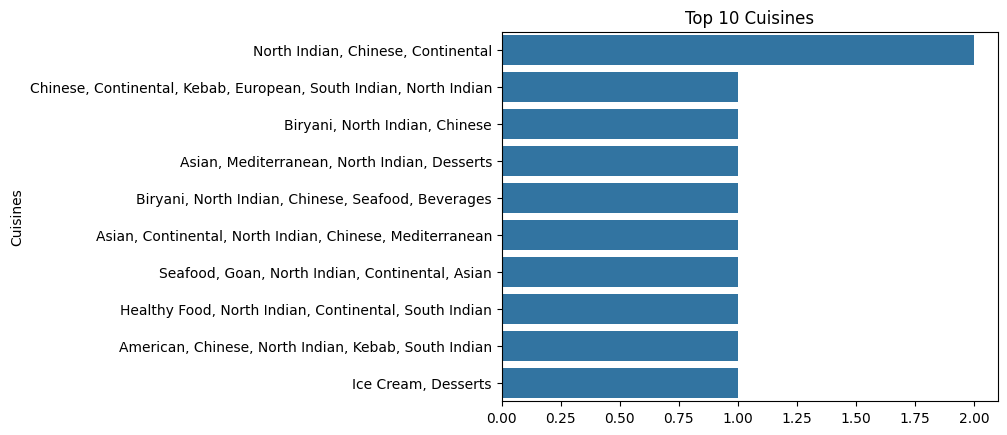

In [14]:
top_cuisines = df['Cuisines'].value_counts().head(10)

plt.figure()
sns.barplot(x=top_cuisines.values, y=top_cuisines.index)
plt.title("Top 10 Cuisines")
plt.show()

## Most Expensive Restaurants

In [15]:
df.sort_values(by='Cost', ascending=False).head()

,Name,Links,Cost,Collections,Cuisines,Timings
92,Collage - Hyatt Hyderabad Gachibowli,https://www.zomato.com/hyderabad/collage-hyatt...,2800.0,Sunday Brunches,"Continental, Italian, North Indian, Chinese, A...",24 Hours (Mon-Sun)
56,Feast - Sheraton Hyderabad Hotel,https://www.zomato.com/hyderabad/feast-sherato...,2500.0,"Sunday Brunches, Great Breakfasts, Function Ve...","Modern Indian, Asian, Continental, Italian","6:30am to 10:30am, 12:30pm to 3pm, 7pm to 11pm..."
21,Jonathan's Kitchen - Holiday Inn Express & Suites,https://www.zomato.com/hyderabad/jonathans-kit...,1900.0,"Great Italian, Sunday Brunches","North Indian, Japanese, Italian, Salad, Sushi","11:30 AM to 3 PM, 7 PM to 11 PM"
18,10 Downing Street,https://www.zomato.com/hyderabad/10-downing-st...,1900.0,Trending This Week,"North Indian, Chinese, Continental",12 Noon to 12 Midnight
104,Republic Of Noodles - Lemon Tree Hotel,https://www.zomato.com/hyderabad/republic-of-n...,1700.0,Pan-Asian Delicacies,"Thai, Asian, Chinese, Malaysian","11:30 AM to 3 PM, 7 PM to 12 Midnight"


Part 2 - Reviews EDA(df1)

## Data Understanding

In [16]:
df1.head()

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


In [17]:
df1.isna().sum()

Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64

In [18]:
df1 = df1.dropna()
df1.isna().sum()

Restaurant    0
Reviewer      0
Review        0
Rating        0
Metadata      0
Time          0
Pictures      0
dtype: int64

In [19]:
df1.info()

<class 'pandas.DataFrame'>
Index: 9955 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Restaurant  9955 non-null   str  
 1   Reviewer    9955 non-null   str  
 2   Review      9955 non-null   str  
 3   Rating      9955 non-null   str  
 4   Metadata    9955 non-null   str  
 5   Time        9955 non-null   str  
 6   Pictures    9955 non-null   int64
dtypes: int64(1), str(6)
memory usage: 622.2 KB


## Rating Distribution

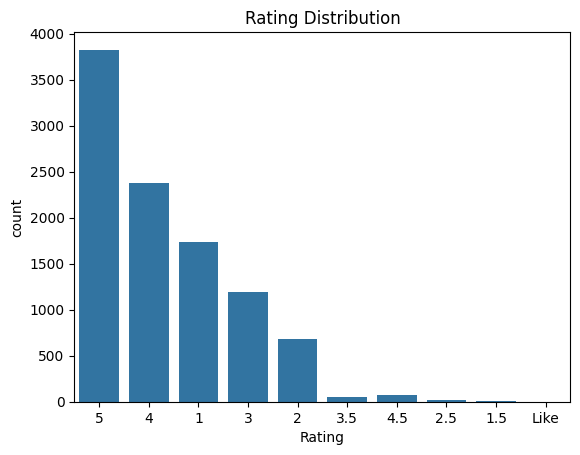

In [20]:
plt.figure()
sns.countplot(x='Rating', data=df1)
plt.title("Rating Distribution")
plt.show()

In [21]:
df1['Rating'] = pd.to_numeric(df1['Rating'], errors='coerce')

In [22]:
df1= df1.dropna(subset=['Rating'])

In [23]:
print("Average Rating:", round(df1['Rating'].mean(), 2))

Average Rating: 3.6


In [24]:
df1['Rating'] = pd.to_numeric(df1['Rating'], errors='coerce')
df['Cost'] = pd.to_numeric(df['Cost'], errors='coerce')

In [25]:
df1['Rating'].dtype

dtype('float64')

## Average Rating

In [26]:
print("Average Rating:", df1['Rating'].mean())

Average Rating: 3.600261201527024


## Top 10 Restaurants (Most Reviewed)

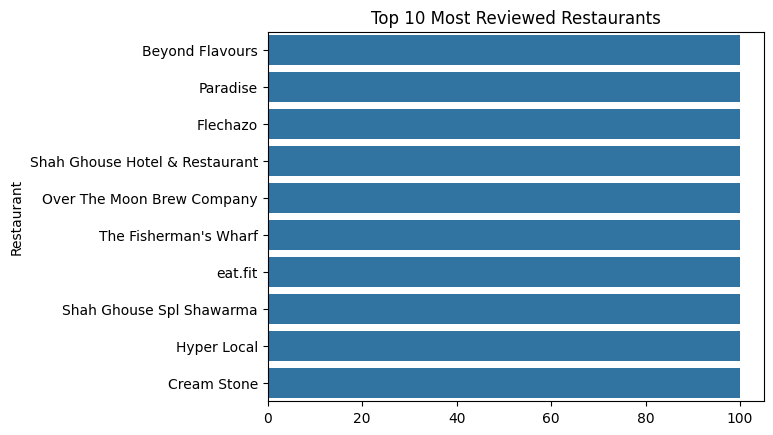

In [27]:
top_rest = df1['Restaurant'].value_counts().head(10)

plt.figure()
sns.barplot(x=top_rest.values, y=top_rest.index)
plt.title("Top 10 Most Reviewed Restaurants")
plt.show()

## Picture Analysis

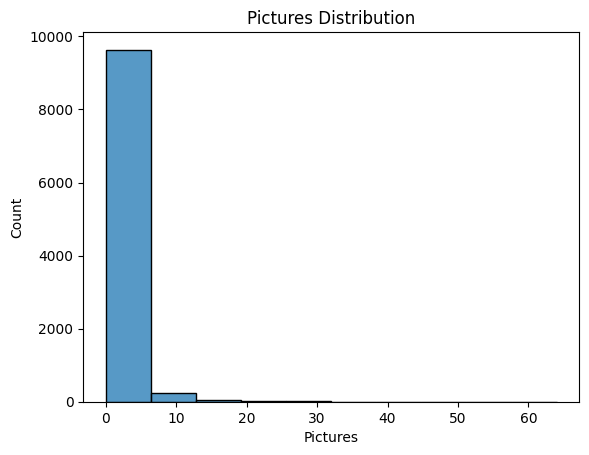

In [28]:
plt.figure()
sns.histplot(df1['Pictures'], bins=10)
plt.title("Pictures Distribution")
plt.show()

## Convert Time to Datetime

In [29]:
df1['Time'] = pd.to_datetime(df1['Time'])
df1['Month'] = df1['Time'].dt.month

## Monthly reviews

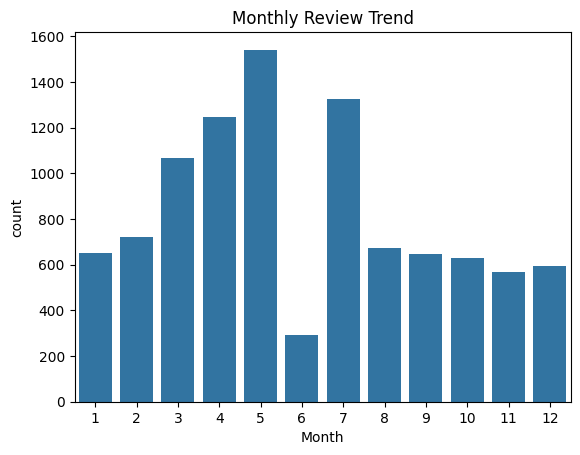

In [30]:
sns.countplot(x='Month', data=df1)
plt.title("Monthly Review Trend")
plt.show()

## Clustering (Metadata Data)

In [31]:
df['Cost'] = df['Cost'].astype(str)
df['Cost'] = df['Cost'].str.replace(',','')
df['Cost'] = pd.to_numeric(df['Cost'], errors='coerce')
df = df.dropna(subset=['Cost'])

In [32]:
type(df['Cost'])

pandas.Series

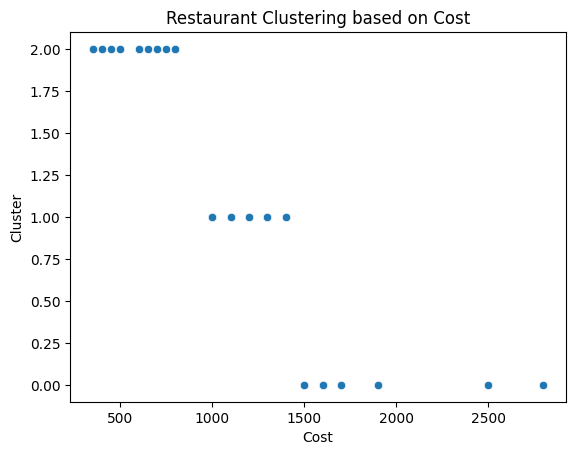

In [33]:
## Feature selection
features = df[['Cost']]

## Scaling
scaler = StandardScaler()
scaled = scaler.fit_transform(features)

## KMeans
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(scaled)

## Plot
sns.scatterplot(x=df['Cost'], y=df['Cluster'])
plt.title("Restaurant Clustering based on Cost")
plt.show()

## Cluster Analysis

In [34]:
df.groupby('Cluster')['Cost'].mean()

Cluster
0    1771.428571
1    1182.352941
2     592.500000
Name: Cost, dtype: float64

In [35]:
df['Cluster'].value_counts()

Cluster
2    20
1    17
0    14
Name: count, dtype: int64

## Cluster Naming

## cluster 0 -> Budget Restaurants
## cluster 1 -> Mid-range Restaurants
## cluster 2 -> Premium Restaurants

 Improve Visualization

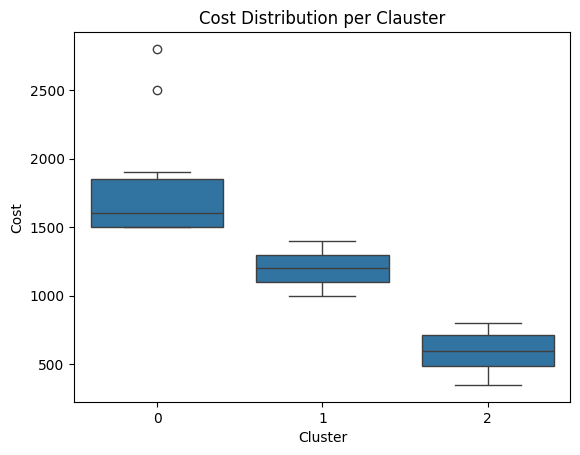

In [36]:
sns.boxplot(x='Cluster', y='Cost', data=df)
plt.title("Cost Distribution per Clauster")
plt.show()

## Merge Reviews + Metadata

In [37]:
merged = pd.merge(df, df1, left_on='Name', right_on='Restaurant')

In [38]:
merged['Rating'] = pd.to_numeric(merged['Rating'], errors='coerce')
merged.groupby('Cluster')['Rating'].mean()

Cluster
0    4.110506
1    3.745588
2    3.556904
Name: Rating, dtype: float64

## Budget 0 -> 4.1
## Mid 1 -> 3.7
## Premium 2 -> 3.5

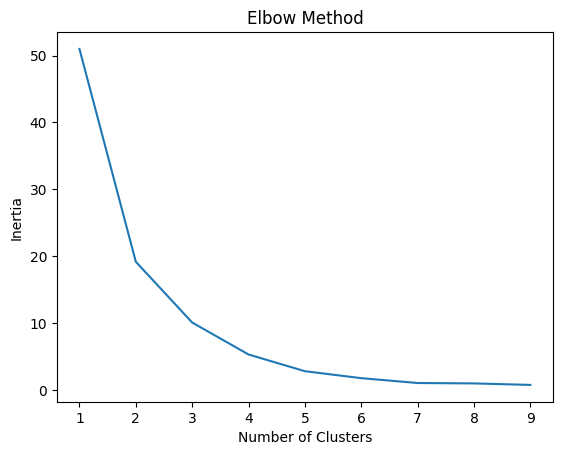

In [39]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
for i in range(1, 10):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 10), inertia)
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

## Assume elbow k=3

In [40]:
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(scaled)

In [41]:
df.groupby('Cluster')['Cost'].mean()

Cluster
0    1771.428571
1    1182.352941
2     592.500000
Name: Cost, dtype: float64

In [42]:
df['Cluster'].value_counts()

Cluster
2    20
1    17
0    14
Name: count, dtype: int64

## Visualization

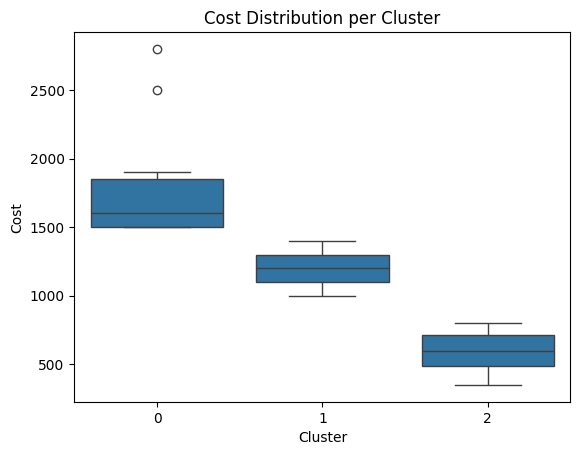

In [43]:
sns.boxplot(x='Cluster', y='Cost', data = df)
plt.title("Cost Distribution per Cluster")
plt.show()

In [44]:
from sklearn.metrics import silhouette_score

score = silhouette_score(scaled, df['Cluster'])
print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.56


In [45]:
df.groupby("Cluster")["Cost"].mean()

Cluster
0    1771.428571
1    1182.352941
2     592.500000
Name: Cost, dtype: float64

In [46]:
df["Cluster"].value_counts()

Cluster
2    20
1    17
0    14
Name: count, dtype: int64

## Visualization

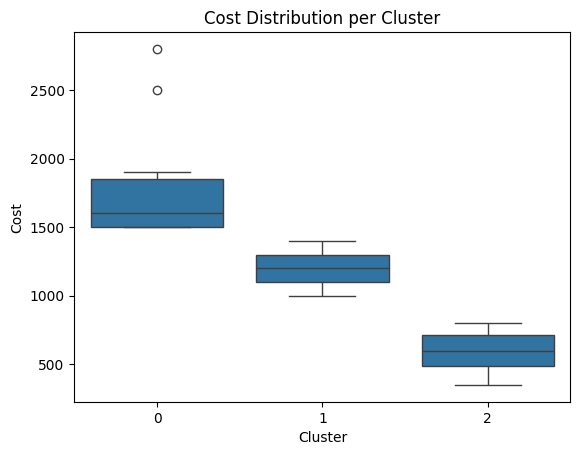

In [47]:
sns.boxplot(x="Cluster", y="Cost", data=df)
plt.title("Cost Distribution per Cluster")
plt.show()

## Cluster Interpretation

In [48]:
df.groupby('Cluster')['Cost'].agg(['mean', 'min', 'max', 'count'])

,mean,min,max,count
Cluster,,,,
0,1771.428571,1500.0,2800.0,14
1,1182.352941,1000.0,1400.0,17
2,592.500000,350.0,800.0,20


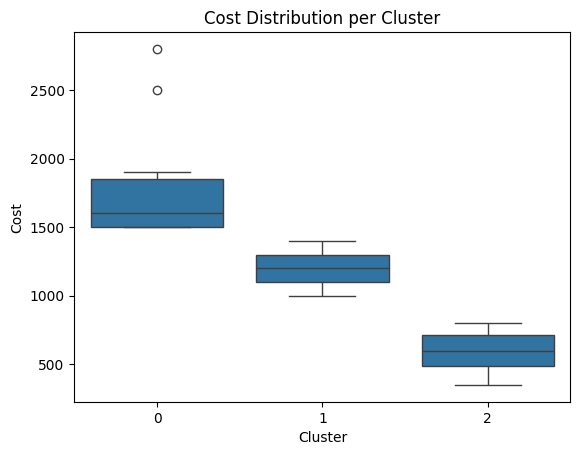

In [49]:
sns.boxplot(x='Cluster', y='Cost', data=df)
plt.title("Cost Distribution per Cluster")
plt.show()